In [2]:

# BBIM707 Part A - Task 1: Data Extraction

import pandas as pd

# Extract the two datasets
orders_df = pd.read_csv("olist_orders_dataset.csv")
customers_df = pd.read_csv("olist_customers_dataset.csv")

# Verify successful extraction
print("ORDERS DATASET")
print("Shape:", orders_df.shape)
display(orders_df.head())

print("\nCUSTOMERS DATASET")
print("Shape:", customers_df.shape)
display(customers_df.head())


ORDERS DATASET
Shape: (99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



CUSTOMERS DATASET
Shape: (99441, 5)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [3]:

# Step 1: Check missing values and duplicate records

for name, df in [("Orders", orders_df), ("Customers", customers_df)]:

    print(f"\n{name.upper()} DATASET")
    print("Dataset Shape:", df.shape)

    # Count missing values in each column
    print("\nMissing Values:")
    display(df.isnull().sum().to_frame("Missing Count"))

    # Check for duplicate records
    print("Duplicate Rows:", df.duplicated().sum())
    print("Duplicate Customer IDs:", df["customer_id"].duplicated().sum())



ORDERS DATASET
Dataset Shape: (99441, 8)

Missing Values:


,Missing Count
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


Duplicate Rows: 0
Duplicate Customer IDs: 0

CUSTOMERS DATASET
Dataset Shape: (99441, 5)

Missing Values:


,Missing Count
customer_id,0
customer_unique_id,0
customer_zip_code_prefix,0
customer_city,0
customer_state,0


Duplicate Rows: 0
Duplicate Customer IDs: 0


In [4]:

# Step 2: Data Cleaning - Handle missing values and remove duplicates

# Create copies to preserve the original extracted datasets
orders_clean = orders_df.copy()
customers_clean = customers_df.copy()

# Remove duplicate records from both datasets
orders_clean = orders_clean.drop_duplicates().copy()
customers_clean = customers_clean.drop_duplicates().copy()

# Convert order date columns into datetime format
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders_clean[col] = pd.to_datetime(
        orders_clean[col], errors="coerce"
    )

# Create indicators to identify missing order-processing dates
orders_clean["approval_date_missing"] = (
    orders_clean["order_approved_at"].isna().astype(int)
)

orders_clean["carrier_date_missing"] = (
    orders_clean["order_delivered_carrier_date"].isna().astype(int)
)

orders_clean["delivery_date_missing"] = (
    orders_clean["order_delivered_customer_date"].isna().astype(int)
)

# Verify cleaned dataset dimensions and duplicate records
print("ORDERS DATASET AFTER CLEANING")
print("Shape:", orders_clean.shape)
print("Duplicate Rows:", orders_clean.duplicated().sum())

print("\nMISSING DATE INDICATORS")
display(
    orders_clean[
        [
            "approval_date_missing",
            "carrier_date_missing",
            "delivery_date_missing"
        ]
    ].sum().to_frame("Missing Count")
)

print("\nCUSTOMERS DATASET AFTER CLEANING")
print("Shape:", customers_clean.shape)
print("Duplicate Rows:", customers_clean.duplicated().sum())


ORDERS DATASET AFTER CLEANING
Shape: (99441, 11)
Duplicate Rows: 0

MISSING DATE INDICATORS


,Missing Count
approval_date_missing,160
carrier_date_missing,1783
delivery_date_missing,2965



CUSTOMERS DATASET AFTER CLEANING
Shape: (99441, 5)
Duplicate Rows: 0


In [5]:

# Step 3: Rename columns and standardise data types

# Rename order date columns for clarity
orders_clean = orders_clean.rename(columns={
    "order_purchase_timestamp": "purchase_date",
    "order_approved_at": "approval_date",
    "order_delivered_carrier_date": "carrier_delivery_date",
    "order_delivered_customer_date": "actual_delivery_date",
    "order_estimated_delivery_date": "estimated_delivery_date"
})

# Rename customer location columns
customers_clean = customers_clean.rename(columns={
    "customer_zip_code_prefix": "zip_code",
    "customer_city": "city",
    "customer_state": "state"
})

# Standardise customer location data
customers_clean["zip_code"] = (
    customers_clean["zip_code"].astype(str).str.zfill(5)
)

customers_clean["city"] = (
    customers_clean["city"].astype("string").str.strip()
)

customers_clean["state"] = (
    customers_clean["state"].astype("string").str.strip().str.upper()
)

# Verify column names and data types
print("ORDERS DATA TYPES")
display(orders_clean.dtypes.to_frame("Data Type"))

print("\nCUSTOMERS DATA TYPES")
display(customers_clean.dtypes.to_frame("Data Type"))

print("\nCUSTOMER LOCATION SAMPLE")
display(customers_clean[["zip_code", "city", "state"]].head())

print("\nDATASET SHAPES")
print("Orders:", orders_clean.shape)
print("Customers:", customers_clean.shape)


ORDERS DATA TYPES


,Data Type
order_id,object
customer_id,object
order_status,object
purchase_date,datetime64[ns]
approval_date,datetime64[ns]
carrier_delivery_date,datetime64[ns]
actual_delivery_date,datetime64[ns]
estimated_delivery_date,datetime64[ns]
approval_date_missing,int64
carrier_date_missing,int64



CUSTOMERS DATA TYPES


,Data Type
customer_id,object
customer_unique_id,object
zip_code,object
city,string[python]
state,string[python]



CUSTOMER LOCATION SAMPLE


,zip_code,city,state
0,14409,franca,SP
1,09790,sao bernardo do campo,SP
2,01151,sao paulo,SP
3,08775,mogi das cruzes,SP
4,13056,campinas,SP



DATASET SHAPES
Orders: (99441, 11)
Customers: (99441, 5)


In [6]:

# Step 4: Create derived fields for analysis

# Extract year, month and weekday from purchase dates
orders_clean["purchase_year"] = (
    orders_clean["purchase_date"].dt.year
)

orders_clean["purchase_month"] = (
    orders_clean["purchase_date"].dt.month
)

orders_clean["purchase_weekday"] = (
    orders_clean["purchase_date"].dt.day_name()
)

# Calculate actual delivery time in days
orders_clean["delivery_days"] = (
    orders_clean["actual_delivery_date"] -
    orders_clean["purchase_date"]
).dt.total_seconds() / 86400

# Calculate the difference between actual and estimated delivery dates
orders_clean["delivery_delay_days"] = (
    orders_clean["actual_delivery_date"] -
    orders_clean["estimated_delivery_date"]
).dt.total_seconds() / 86400

# Create a delivery performance category
import numpy as np

orders_clean["delivery_performance"] = np.select(
    [
        orders_clean["actual_delivery_date"].isna(),
        orders_clean["delivery_delay_days"] <= 0
    ],
    [
        "Not Delivered",
        "On Time"
    ],
    default="Late"
)

# Verify the new derived fields
print("ORDERS DATASET AFTER FEATURE ENGINEERING")
print("Shape:", orders_clean.shape)

print("\nDERIVED FIELD SAMPLE")
display(
    orders_clean[
        [
            "purchase_year",
            "purchase_month",
            "purchase_weekday",
            "delivery_days",
            "delivery_delay_days",
            "delivery_performance"
        ]
    ].head(10)
)

print("\nDELIVERY PERFORMANCE DISTRIBUTION")
display(
    orders_clean["delivery_performance"]
    .value_counts()
    .to_frame("Order Count")
)


ORDERS DATASET AFTER FEATURE ENGINEERING
Shape: (99441, 17)

DERIVED FIELD SAMPLE


,purchase_year,purchase_month,purchase_weekday,delivery_days,delivery_delay_days,delivery_performance
0,2017,10,Monday,8.436574,-7.107488,On Time
1,2018,7,Tuesday,13.782037,-5.355729,On Time
2,2018,8,Wednesday,9.394213,-17.245498,On Time
3,2017,11,Saturday,13.208750,-12.980069,On Time
4,2018,2,Tuesday,2.873877,-9.238171,On Time
5,2017,7,Sunday,16.542245,-5.543113,On Time
6,2017,4,Tuesday,NaN,NaN,Not Delivered
7,2017,5,Tuesday,9.989826,-11.461215,On Time
8,2017,1,Monday,9.818762,-31.410995,On Time
9,2017,7,Saturday,18.221852,-6.281597,On Time



DELIVERY PERFORMANCE DISTRIBUTION


,Order Count
delivery_performance,
On Time,88649
Late,7827
Not Delivered,2965


In [7]:

# Step 5: Verify transformed data quality and integrity

print("FINAL TRANSFORMATION VERIFICATION")

# Confirm dataset dimensions and unique identifiers
print("\nORDERS DATASET")
print("Shape:", orders_clean.shape)
print("Duplicate Order IDs:", orders_clean["order_id"].duplicated().sum())
print("Duplicate Customer IDs:", orders_clean["customer_id"].duplicated().sum())

print("\nCUSTOMERS DATASET")
print("Shape:", customers_clean.shape)
print("Duplicate Customer IDs:", customers_clean["customer_id"].duplicated().sum())

# Verify all order customer IDs exist in the Customers dataset
unmatched_ids = ~orders_clean["customer_id"].isin(
    customers_clean["customer_id"]
)

print("\nUnmatched Customer IDs:", unmatched_ids.sum())

# Check invalid delivery durations and classification completeness
print("Negative Delivery Durations:",
      (orders_clean["delivery_days"] < 0).sum())

print("Missing Delivery Performance:",
      orders_clean["delivery_performance"].isna().sum())

# Confirm datetime conversion and missing date counts
print("\nDATE VALIDATION")
for col in [
    "purchase_date",
    "approval_date",
    "carrier_delivery_date",
    "actual_delivery_date",
    "estimated_delivery_date"
]:
    print(col, "| Type:", orders_clean[col].dtype,
          "| Missing:", orders_clean[col].isna().sum())

# Verify final dataset sizes
assert len(orders_clean) == 99441
assert len(customers_clean) == 99441

print("\nTransformation verification completed.")


FINAL TRANSFORMATION VERIFICATION

ORDERS DATASET
Shape: (99441, 17)
Duplicate Order IDs: 0
Duplicate Customer IDs: 0

CUSTOMERS DATASET
Shape: (99441, 5)
Duplicate Customer IDs: 0

Unmatched Customer IDs: 0
Negative Delivery Durations: 0
Missing Delivery Performance: 0

DATE VALIDATION
purchase_date | Type: datetime64[ns] | Missing: 0
approval_date | Type: datetime64[ns] | Missing: 160
carrier_delivery_date | Type: datetime64[ns] | Missing: 1783
actual_delivery_date | Type: datetime64[ns] | Missing: 2965
estimated_delivery_date | Type: datetime64[ns] | Missing: 0

Transformation verification completed.


In [8]:

#Part A — Task 1 (III): Data Loading and Integration 
# Step 1: Integrate cleaned Orders and Customers datasets

# Merge both datasets using the common customer_id
integrated_df = pd.merge(
    orders_clean,
    customers_clean,
    on="customer_id",
    how="inner",
    validate="one_to_one"
)

# Verify the integrated dataset
print("INTEGRATED DATASET VERIFICATION")
print("Dataset Shape:", integrated_df.shape)
print("Total Records:", len(integrated_df))
print("Total Columns:", len(integrated_df.columns))

# Check duplicate records and missing customer identifiers
print("Duplicate Order IDs:",
      integrated_df["order_id"].duplicated().sum())

print("Missing Customer IDs:",
      integrated_df["customer_id"].isnull().sum())

# Display selected columns from the integrated dataset
print("\nINTEGRATED DATASET SAMPLE")
display(
    integrated_df[
        [
            "order_id",
            "customer_id",
            "order_status",
            "purchase_date",
            "delivery_performance",
            "city",
            "state"
        ]
    ].head(10)
)


INTEGRATED DATASET VERIFICATION
Dataset Shape: (99441, 21)
Total Records: 99441
Total Columns: 21
Duplicate Order IDs: 0
Missing Customer IDs: 0

INTEGRATED DATASET SAMPLE


,order_id,customer_id,order_status,purchase_date,delivery_performance,city,state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,On Time,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,On Time,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,On Time,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,On Time,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,On Time,santo andre,SP
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,On Time,congonhinhas,PR
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,Not Delivered,santa rosa,RS
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,On Time,nilopolis,RJ
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,On Time,faxinalzinho,RS
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,On Time,sorocaba,SP


In [9]:

# Step 2: Save and reload the integrated dataset

import pandas as pd
from pathlib import Path

# Save the unified dataset as a CSV file
output_path = Path("olist_integrated_clean.csv")
integrated_df.to_csv(output_path, index=False)

# Reload the saved dataset to verify successful loading
loaded_df = pd.read_csv(
    output_path,
    parse_dates=[
        "purchase_date",
        "approval_date",
        "carrier_delivery_date",
        "actual_delivery_date",
        "estimated_delivery_date"
    ],
    dtype={"zip_code": "string"}
)

# Check dataset dimensions and record integrity
print("DATA LOADING VERIFICATION")
print("Saved File:", output_path)
print("Original Shape:", integrated_df.shape)
print("Reloaded Shape:", loaded_df.shape)

print("Record Count Match:",
      len(integrated_df) == len(loaded_df))

print("Column Names Match:",
      integrated_df.columns.tolist() == loaded_df.columns.tolist())

print("Duplicate Order IDs:",
      loaded_df["order_id"].duplicated().sum())

print("Missing Customer IDs:",
      loaded_df["customer_id"].isna().sum())

# Verify the saved file exists
print("File Exists:", output_path.exists())

print("\nRELOADED DATASET SAMPLE")
display(
    loaded_df[
        [
            "order_id",
            "order_status",
            "purchase_date",
            "delivery_performance",
            "city",
            "state"
        ]
    ].head()
)


DATA LOADING VERIFICATION
Saved File: olist_integrated_clean.csv
Original Shape: (99441, 21)
Reloaded Shape: (99441, 21)
Record Count Match: True
Column Names Match: True
Duplicate Order IDs: 0
Missing Customer IDs: 0
File Exists: True

RELOADED DATASET SAMPLE


,order_id,order_status,purchase_date,delivery_performance,city,state
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,2017-10-02 10:56:33,On Time,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,2018-07-24 20:41:37,On Time,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,2018-08-08 08:38:49,On Time,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,2017-11-18 19:28:06,On Time,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,2018-02-13 21:18:39,On Time,santo andre,SP


In [10]:
## Part A taskB
# Step 1: Generate descriptive statistics for the integrated dataset
# Use the successfully loaded and verified dataset
analysis_df = loaded_df.copy()

# Select meaningful numerical fields for analysis
numeric_columns = [
    "delivery_days",
    "delivery_delay_days",
    "purchase_year",
    "purchase_month"
]

# Calculate descriptive statistics
print("DESCRIPTIVE STATISTICS OF INTEGRATED DATASET")
display(
    analysis_df[numeric_columns]
    .describe()
    .round(2)
)

# Summarise overall dataset characteristics
print("\nDATASET SUMMARY")
print("Total Records:", len(analysis_df))
print("Total Columns:", len(analysis_df.columns))
print("Unique Orders:", analysis_df["order_id"].nunique())
print("Unique Customers:", analysis_df["customer_unique_id"].nunique())

# Calculate delivery performance statistics
print("\nDELIVERY PERFORMANCE SUMMARY")
print(
    "Average Delivery Time (Days):",
    round(analysis_df["delivery_days"].mean(), 2)
)
print(
    "Median Delivery Time (Days):",
    round(analysis_df["delivery_days"].median(), 2)
)
print(
    "Average Delivery Delay (Days):",
    round(analysis_df["delivery_delay_days"].mean(), 2)
)


DESCRIPTIVE STATISTICS OF INTEGRATED DATASET


,delivery_days,delivery_delay_days,purchase_year,purchase_month
count,96476.00,96476.00,99441.00,99441.00
mean,12.56,-11.18,2017.54,6.03
std,9.55,10.19,0.51,3.23
min,0.53,-146.02,2016.00,1.00
25%,6.77,-16.24,2017.00,3.00
50%,10.22,-11.95,2018.00,6.00
75%,15.72,-6.39,2018.00,8.00
max,209.63,188.98,2018.00,12.00



DATASET SUMMARY
Total Records: 99441
Total Columns: 21
Unique Orders: 99441
Unique Customers: 96096

DELIVERY PERFORMANCE SUMMARY
Average Delivery Time (Days): 12.56
Median Delivery Time (Days): 10.22
Average Delivery Delay (Days): -11.18


In [11]:

# Step 2: Frequency analysis of three key categorical columns

# Select three relevant categorical variables
categorical_columns = [
    "order_status",
    "delivery_performance",
    "state"
]

for col in categorical_columns:

    print(f"\n{col.upper()} - FREQUENCY DISTRIBUTION")

    # Calculate the number and percentage of records per category
    frequency_table = pd.DataFrame({
        "Count": analysis_df[col].value_counts(),
        "Percentage (%)": (
            analysis_df[col].value_counts(normalize=True) * 100
        ).round(2)
    })

    display(frequency_table)

    # Verify the total number of records counted
    print("Total Records Counted:", frequency_table["Count"].sum())



ORDER_STATUS - FREQUENCY DISTRIBUTION


,Count,Percentage (%)
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


Total Records Counted: 99441

DELIVERY_PERFORMANCE - FREQUENCY DISTRIBUTION


,Count,Percentage (%)
delivery_performance,,
On Time,88649,89.15
Late,7827,7.87
Not Delivered,2965,2.98


Total Records Counted: 99441

STATE - FREQUENCY DISTRIBUTION


,Count,Percentage (%)
state,,
SP,41746,41.98
RJ,12852,12.92
MG,11635,11.70
RS,5466,5.50
PR,5045,5.07
SC,3637,3.66
BA,3380,3.40
DF,2140,2.15
ES,2033,2.04


Total Records Counted: 99441


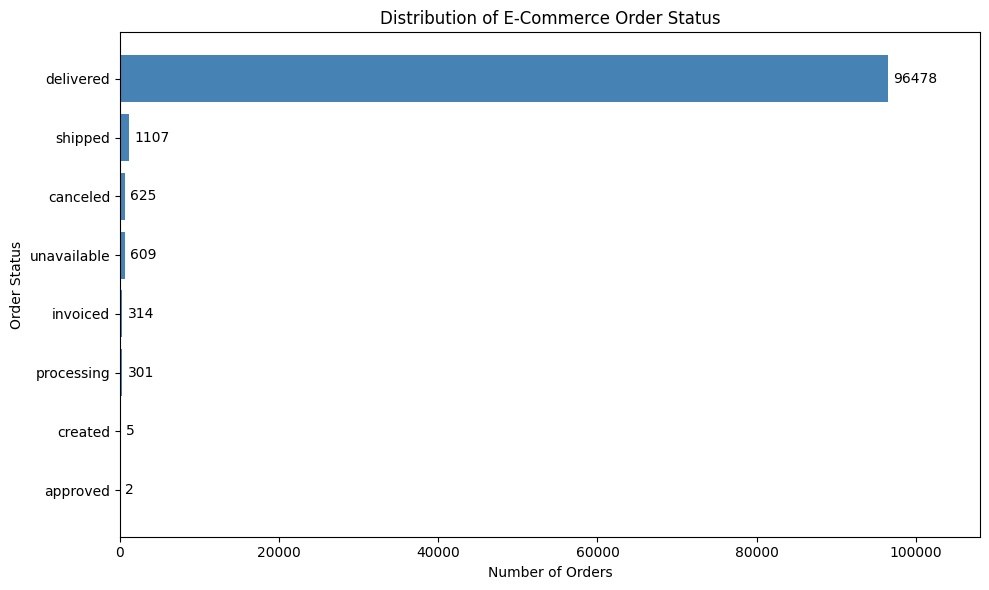

In [12]:

# Step 3: Visualise order status distribution

import matplotlib.pyplot as plt

# Calculate order counts by status
status_counts = analysis_df["order_status"].value_counts()

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))
bars = plt.barh(
    status_counts.index,
    status_counts.values,
    color="steelblue"
)

# Add order counts to each bar
plt.bar_label(bars, padding=4, fmt="%d")

# Format chart labels and layout
plt.title("Distribution of E-Commerce Order Status")
plt.xlabel("Number of Orders")
plt.ylabel("Order Status")
plt.gca().invert_yaxis()
plt.xlim(0, status_counts.max() * 1.12)
plt.tight_layout()

plt.show()


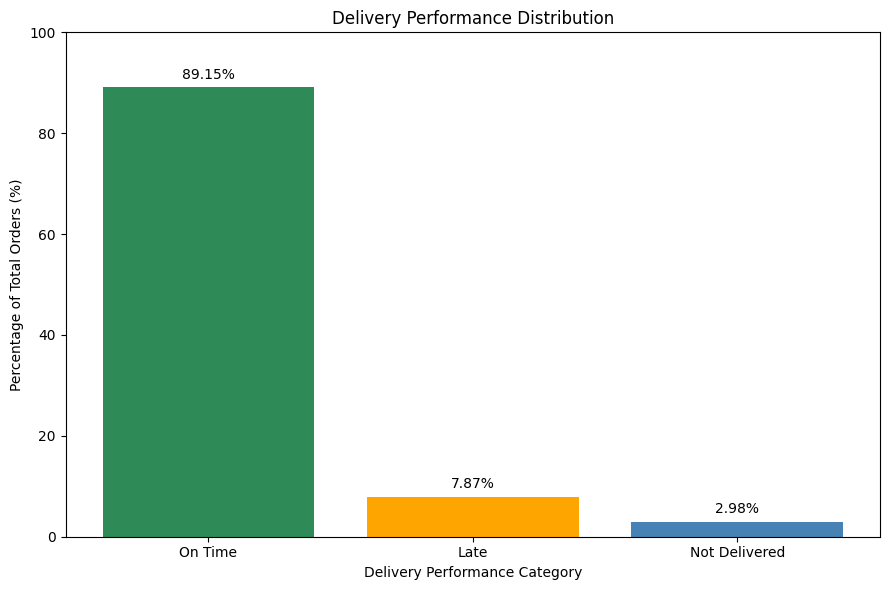

In [13]:

# Step 4: Visualise delivery performance distribution

import matplotlib.pyplot as plt

# Calculate delivery performance counts and percentages
performance_counts = analysis_df["delivery_performance"].value_counts()
performance_percentages = (
    analysis_df["delivery_performance"].value_counts(normalize=True) * 100
)

# Create the delivery performance bar chart
plt.figure(figsize=(9, 6))

bars = plt.bar(
    performance_counts.index,
    performance_percentages.values,
    color=["seagreen", "orange", "steelblue"]
)

# Display percentages above each bar
plt.bar_label(bars, fmt="%.2f%%", padding=4)

# Format chart titles and axes
plt.title("Delivery Performance Distribution")
plt.xlabel("Delivery Performance Category")
plt.ylabel("Percentage of Total Orders (%)")
plt.ylim(0, 100)
plt.tight_layout()

plt.show()


In [14]:
# Part B – Task 1: HDFS Data Ingestion Pipeline

## Step 1: Hadoop and HDFS Environment Verification

# Step 1: Verify Hadoop and HDFS availability

import shutil

# Check if Hadoop and HDFS commands are installed
hadoop_path = shutil.which("hadoop")
hdfs_path = shutil.which("hdfs")

print("HADOOP ENVIRONMENT VERIFICATION")
print("Hadoop Command:", hadoop_path)
print("HDFS Command:", hdfs_path)

if hadoop_path and hdfs_path:
    print("Hadoop command-line tools are available.")
else:
    print("Hadoop command-line tools are not available.")


HADOOP ENVIRONMENT VERIFICATION
Hadoop Command: None
HDFS Command: None
Hadoop command-line tools are not available.


In [16]:

from pathlib import Path

print("Current working directory:", Path.cwd())

# Search common folders for Olist files
folders = [
    Path.home() / "Downloads",
    Path.home() / "Documents",
    Path.home() / "Desktop",
    Path.cwd()
]

for folder in folders:
    if folder.exists():
        for file in folder.rglob("*olist*"):
            if file.is_file():
                print(file)


Current working directory: C:\Users\HP
C:\Users\HP\Downloads\olist_customers_dataset.csv.zip
C:\Users\HP\Downloads\olist_integrated_clean.xls
C:\Users\HP\Downloads\olist_orders_dataset.csv.zip
C:\Users\HP\Downloads\use(BBIM707_Olist_DB)mongodb.txt
C:\Users\HP\Downloads\olist_customers_dataset.csv\olist_customers_dataset.csv
C:\Users\HP\Downloads\olist_orders_dataset.csv\olist_orders_dataset.csv
C:\Users\HP\olist_customers_dataset.csv
C:\Users\HP\olist_integrated_clean.csv
C:\Users\HP\olist_orders_dataset.csv
C:\Users\HP\Downloads\olist_customers_dataset.csv.zip
C:\Users\HP\Downloads\olist_integrated_clean.xls
C:\Users\HP\Downloads\olist_orders_dataset.csv.zip
C:\Users\HP\Downloads\use(BBIM707_Olist_DB)mongodb.txt
C:\Users\HP\miniconda3\pkgs\pandas-2.2.3-py313h5da7b33_0\Lib\site-packages\pandas\tests\series\methods\test_tolist.py
C:\Users\HP\miniconda3\pkgs\pandas-2.2.3-py313h5da7b33_0\Lib\site-packages\pandas\tests\series\methods\__pycache__\test_tolist.cpython-313.pyc
C:\Users\HP\mini

In [17]:

from pathlib import Path
import shutil

source = Path(r"C:\Users\HP\olist_integrated_clean.csv")
destination = Path(r"C:\Users\HP\Downloads\olist_integrated_clean.csv")

if source.exists():
    shutil.copy2(source, destination)
    print("CSV copied successfully!")
    print("File location:", destination)
    print("File size:", round(destination.stat().st_size / 1024**2, 2), "MB")
else:
    print("Source file not found.")



CSV copied successfully!
File location: C:\Users\HP\Downloads\olist_integrated_clean.csv
File size: 27.11 MB


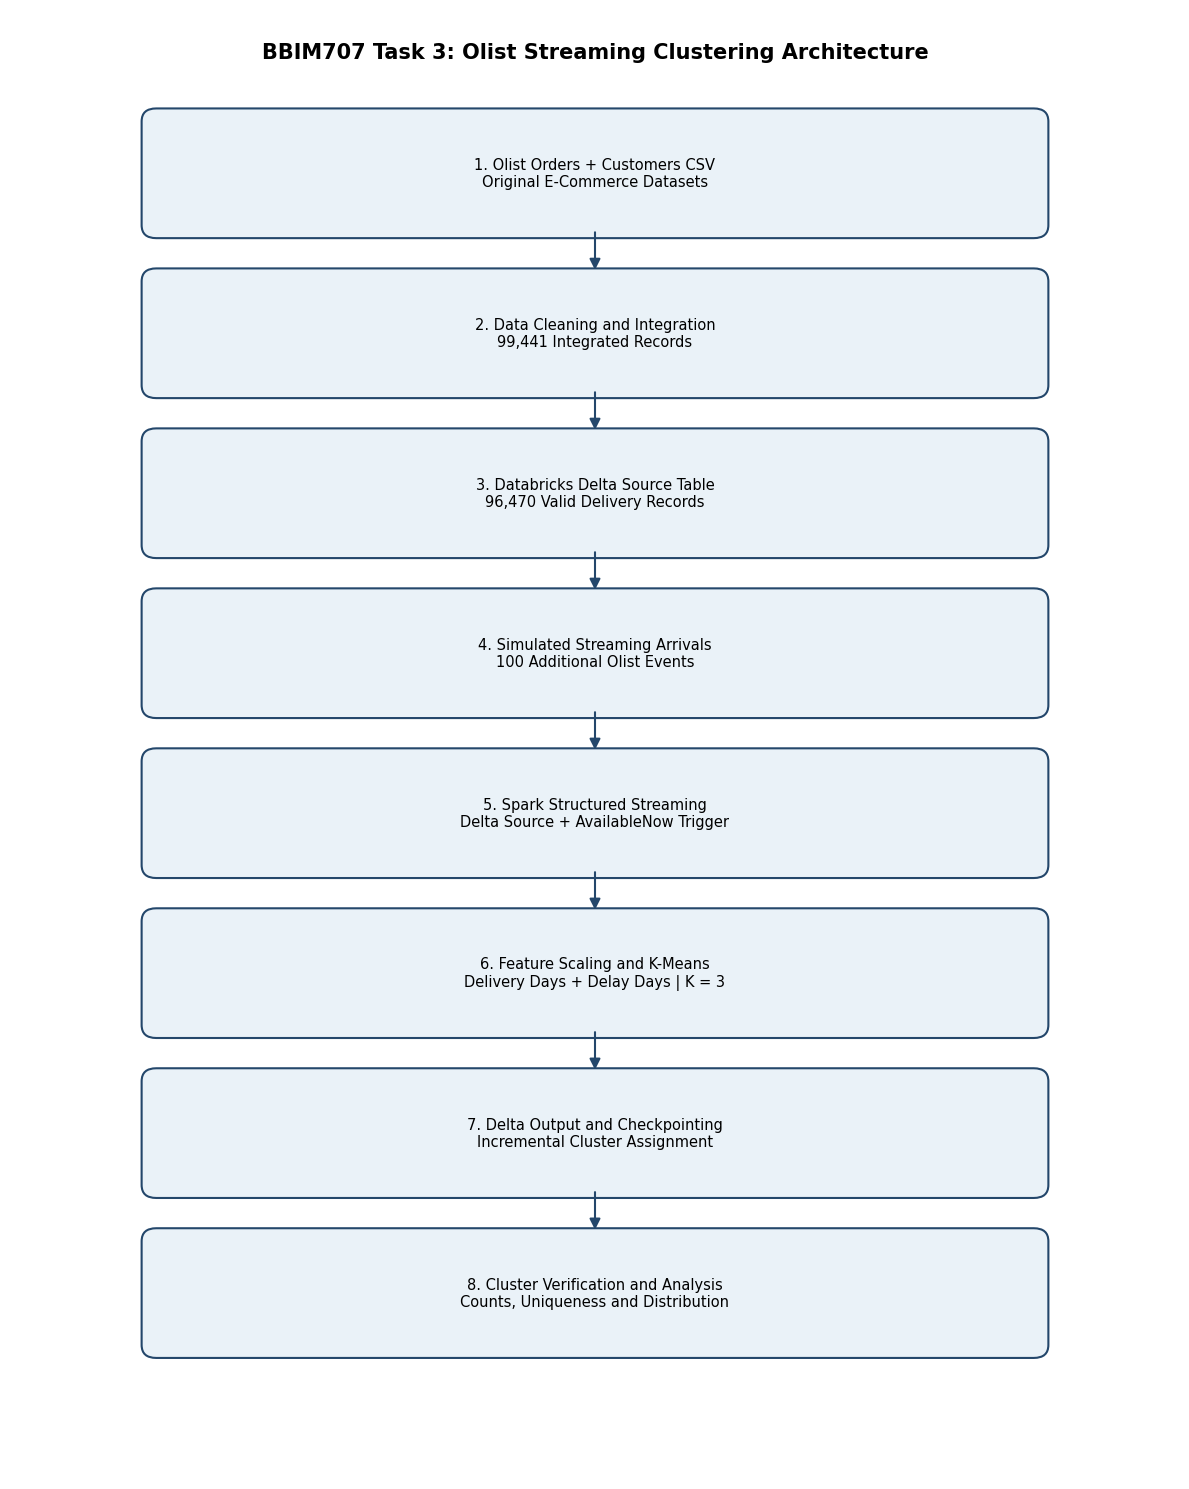

Diagram created successfully!
Saved as: BBIM707_Task3_Streaming_Architecture.png


In [18]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# Eight steps of the actual BBIM707 Task 3 pipeline
steps = [
    "1. Olist Orders + Customers CSV\nOriginal E-Commerce Datasets",
    "2. Data Cleaning and Integration\n99,441 Integrated Records",
    "3. Databricks Delta Source Table\n96,470 Valid Delivery Records",
    "4. Simulated Streaming Arrivals\n100 Additional Olist Events",
    "5. Spark Structured Streaming\nDelta Source + AvailableNow Trigger",
    "6. Feature Scaling and K-Means\nDelivery Days + Delay Days | K = 3",
    "7. Delta Output and Checkpointing\nIncremental Cluster Assignment",
    "8. Cluster Verification and Analysis\nCounts, Uniqueness and Distribution"
]

fig, ax = plt.subplots(figsize=(12, 15))
ax.set_xlim(0, 12)
ax.set_ylim(0, 17)
ax.axis("off")

# Diagram title
ax.text(
    6, 16.5,
    "BBIM707 Task 3: Olist Streaming Clustering Architecture",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold"
)

# Draw boxes and connecting arrows
for i, step in enumerate(steps):
    y = 14.5 - i * 1.85

    box = FancyBboxPatch(
        (1.5, y),
        9, 1.2,
        boxstyle="round,pad=0.15",
        linewidth=1.5,
        edgecolor="#24476B",
        facecolor="#EAF2F8"
    )

    ax.add_patch(box)

    ax.text(
        6, y + 0.6,
        step,
        ha="center",
        va="center",
        fontsize=10.5,
        fontweight="medium"
    )

    if i < len(steps) - 1:
        arrow = FancyArrowPatch(
            (6, y - 0.05),
            (6, y - 0.55),
            arrowstyle="-|>",
            mutation_scale=16,
            linewidth=1.5,
            color="#24476B"
        )
        ax.add_patch(arrow)

plt.tight_layout()

# Save the diagram
plt.savefig(
    "BBIM707_Task3_Streaming_Architecture.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Diagram created successfully!")
print("Saved as: BBIM707_Task3_Streaming_Architecture.png")
